# **i210547 Haider Rizvi**

In [2]:
# Core
import pandas as pd
import numpy as np
import re
import string
import random

# Visualization / EDA
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing / NLP
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Ensure nltk data is downloaded
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')


# Optional: warnings filter
import warnings
warnings.filterwarnings("ignore")
import torch

# Set seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\mhrizvi28\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mhrizvi28\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\mhrizvi28\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\mhrizvi28\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


# **Task 1: Data Preprocessing & EDA**

***• Load your finance dataset***

In [3]:
# File path to the dataset
dataset_path = "dataset/FinancialPhraseBank-v1.0/Sentences_75Agree.txt"



In [4]:
data = pd.read_csv(dataset_path, sep='@', header=None, names=['sentence', 'sentiment'], engine='python', encoding='latin1')
data.head()

,sentence,sentiment
0,"According to Gran , the company has no plans t...",neutral
1,With the new production plant the company woul...,positive
2,"For the last quarter of 2010 , Componenta 's n...",positive
3,"In the third quarter of 2010 , net sales incre...",positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive


***• Clean and preprocess text (lowercase, punctuation removal, tokenization, stopword
removal)***

In [5]:
# Initialize stopwords list and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [6]:
# Define preprocessing function
def preprocess_text(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize
    tokens = nltk.word_tokenize(text)

    # 4. Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # 5. Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Return cleaned text as a string
    return ' '.join(tokens)

In [7]:
#  Apply preprocessing to the 'sentence' column
data['cleaned_sentence'] = data['sentence'].apply(preprocess_text)

# Inspect the first 5 cleaned sentences
data[['sentence', 'cleaned_sentence', 'sentiment']].head()

,sentence,cleaned_sentence,sentiment
0,"According to Gran , the company has no plans t...",according gran company plan move production ru...,neutral
1,With the new production plant the company woul...,new production plant company would increase ca...,positive
2,"For the last quarter of 2010 , Componenta 's n...",last quarter componenta net sale doubled eurm ...,positive
3,"In the third quarter of 2010 , net sales incre...",third quarter net sale increased eur mn operat...,positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,operating profit rose eur mn eur mn correspond...,positive


cleaned_sentence column now contains lowercased, tokenized, stopword-removed, lemmatized sentences, exactly what is needed for both LDA topic modeling and sentiment analysis.

***• Provide basic dataset insights (class balance, sample sentences, length distribution)***

Class distribution:
 sentiment
neutral     2146
positive     887
negative     420
Name: count, dtype: int64


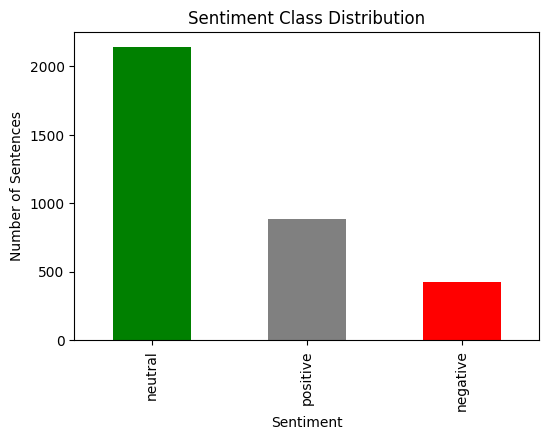

In [8]:
# Class balance
class_counts = data['sentiment'].value_counts()
print("Class distribution:\n", class_counts)

# Plot class balance
plt.figure(figsize=(6,4))
class_counts.plot(kind='bar', color=['green', 'gray', 'red'])
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Sentences')
plt.show()


Class Balance Insights

Neutral: 2,146 sentences → ~62% of dataset

Positive: 887 sentences → ~26% of dataset

Negative: 420 sentences → ~12% of dataset

Implications:

The dataset is heavily skewed toward neutral sentences.

For sentiment modeling, this imbalance may affect metrics like accuracy, so later we might consider:

Using class-weighted loss in training

Oversampling minority classes or downsampling neutral class (if needed)

For LDA topic modeling, class balance does not matter — we can use all sentences.

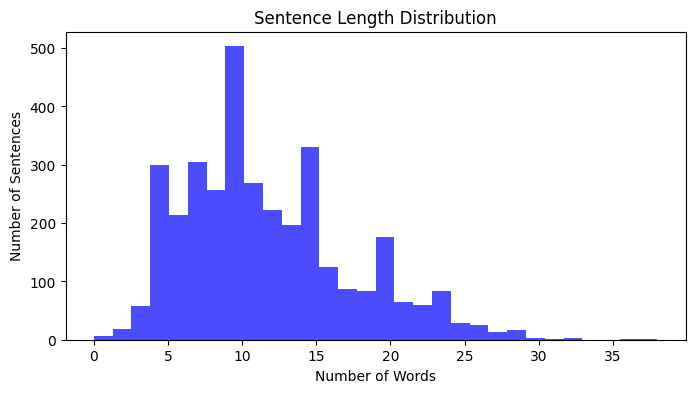

In [9]:
# Sentence length distribution
data['sentence_length'] = data['cleaned_sentence'].apply(lambda x: len(x.split()))
plt.figure(figsize=(8,4))
plt.hist(data['sentence_length'], bins=30, color='blue', alpha=0.7)
plt.title('Sentence Length Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Number of Sentences')
plt.show()

In [10]:

# Display some sample sentences
data.sample(5)[['sentence', 'cleaned_sentence', 'sentiment']]

,sentence,cleaned_sentence,sentiment
511,Turnover surged to EUR61 .8 m from EUR47 .6 m ...,turnover surged eur eur due increasing service...,positive
51,In June it sold a 30 percent stake to Nordstje...,june sold percent stake nordstjernan investmen...,neutral
1886,Aspo 's Group structure and business operation...,aspo group structure business operation contin...,neutral
765,The device can also be used for theft protecti...,device also used theft protection positioning ...,neutral
557,"Of the price , Kesko 's share is 10 mln euro $...",price kesko share mln euro mln recognize gain ...,positive


# **Task 2: Topic Modeling (LDA)**

***• Perform LDA topic modeling***

LDA in Python expects tokenized sentences (list of words, not a single string).

So convert your cleaned_sentence column into lists of words.

In [11]:
# Convert cleaned sentences into lists of words
data['tokens'] = data['cleaned_sentence'].apply(lambda x: x.split())

# Inspect first 5 tokenized sentences
data[['cleaned_sentence', 'tokens']].head()


,cleaned_sentence,tokens
0,according gran company plan move production ru...,"[according, gran, company, plan, move, product..."
1,new production plant company would increase ca...,"[new, production, plant, company, would, incre..."
2,last quarter componenta net sale doubled eurm ...,"[last, quarter, componenta, net, sale, doubled..."
3,third quarter net sale increased eur mn operat...,"[third, quarter, net, sale, increased, eur, mn..."
4,operating profit rose eur mn eur mn correspond...,"[operating, profit, rose, eur, mn, eur, mn, co..."


Each sentence is now a list of cleaned words, ready for LDA topic modeling.

In [12]:
#Import gensim libraries
import gensim
from gensim import corpora
from pprint import pprint
from gensim.models import LdaModel, CoherenceModel

In [13]:
# Create a dictionary of all words
dictionary = corpora.Dictionary(data['tokens'])

# Create a Bag-of-Words corpus
corpus = [dictionary.doc2bow(text) for text in data['tokens']]



***• experiment with multiple topic numbers and compute their coherence scores.***

In [14]:
# Topic numbers to try
topic_nums = [3, 5, 7, 10]

# Store results
lda_models = {}
coherence_scores = {}

for num in topic_nums:
    print(f"\nTraining LDA with {num} topics...")

    # Train LDA
    lda = LdaModel(corpus=corpus,
                   id2word=dictionary,
                   num_topics=num,
                   random_state=42,
                   passes=10,
                   alpha='auto',
                   per_word_topics=True)

    # Save model
    lda_models[num] = lda

    # Compute coherence
    coherence_model = CoherenceModel(model=lda, texts=data['tokens'], dictionary=dictionary, coherence='c_v')
    coherence = coherence_model.get_coherence()
    coherence_scores[num] = coherence

    # Print top 10 words for each topic
    print("\nTop 10 words per topic:")
    for topic_id, topic_words in lda.print_topics(num_words=10):
        print(f"Topic {topic_id}: {topic_words}")

    print(f"\nCoherence Score: {coherence:.4f}")


Training LDA with 3 topics...

Top 10 words per topic:
Topic 0: 0.075*"eur" + 0.043*"mn" + 0.027*"profit" + 0.020*"net" + 0.019*"operating" + 0.018*"sale" + 0.015*"quarter" + 0.014*"period" + 0.014*"million" + 0.010*"compared"
Topic 1: 0.021*"share" + 0.019*"company" + 0.015*"mln" + 0.010*"million" + 0.009*"euro" + 0.009*"said" + 0.008*"eur" + 0.008*"year" + 0.007*"sale" + 0.007*"finnish"
Topic 2: 0.015*"company" + 0.008*"said" + 0.007*"business" + 0.007*"finland" + 0.006*"service" + 0.006*"market" + 0.006*"finnish" + 0.005*"operation" + 0.005*"new" + 0.005*"group"

Coherence Score: 0.3996

Training LDA with 5 topics...

Top 10 words per topic:
Topic 0: 0.009*"company" + 0.006*"also" + 0.006*"finland" + 0.005*"finnish" + 0.005*"helsinki" + 0.005*"people" + 0.005*"omx" + 0.005*"board" + 0.004*"bank" + 0.004*"general"
Topic 1: 0.028*"million" + 0.027*"eur" + 0.025*"share" + 0.022*"company" + 0.020*"mln" + 0.017*"net" + 0.015*"euro" + 0.015*"sale" + 0.012*"year" + 0.011*"said"
Topic 2: 0

**Observation:**

The highest coherence is with 5 topics (0.4239).

3 topics is close, but slightly lower.

7 and 10 topics give lower coherence, probably splitting topics too finely.

So we should choose 5 topics for further analysis.

***Assign Dominant Topic to Each Sentence***

In [15]:
# Pick the best LDA model
best_lda = lda_models[5]

# Assign dominant topic for each sentence
def get_dominant_topic(lda_model, bow):
    topic_probs = lda_model.get_document_topics(bow)
    # Sort topics by probability and take the highest
    dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
    return dominant_topic

# Add dominant topic to dataframe
data['dominant_topic'] = [get_dominant_topic(best_lda, doc) for doc in corpus]

# Display first 5 rows
data[['sentence', 'dominant_topic', 'sentiment']].head()


,sentence,dominant_topic,sentiment
0,"According to Gran , the company has no plans t...",1,neutral
1,With the new production plant the company woul...,2,positive
2,"For the last quarter of 2010 , Componenta 's n...",1,positive
3,"In the third quarter of 2010 , net sales incre...",3,positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,3,positive


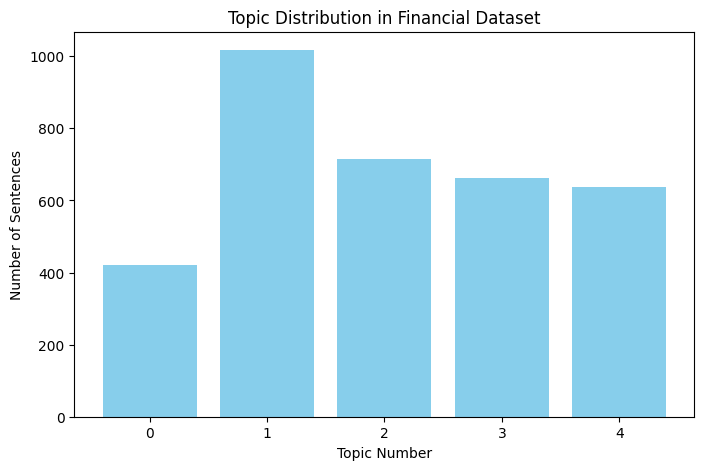

In [16]:
# Count sentences per topic
topic_counts = data['dominant_topic'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,5))
plt.bar(topic_counts.index, topic_counts.values, color='skyblue') # type: ignore
plt.xlabel('Topic Number')
plt.ylabel('Number of Sentences')
plt.title('Topic Distribution in Financial Dataset')
plt.xticks(topic_counts.index)
plt.show()


***• Briefly interpret each topic (e.g., “market movement”, “company performance”, etc.)***

| Topic | Keywords (Top 5)                             | Interpretation                      |
| ----- | -------------------------------------------- | ----------------------------------- |
| 0     | company, finland, helsinki, board, bank      | Company & General News / Governance |
| 1     | million, eur, share, net, sale               | Financial Performance / Earnings    |
| 2     | company, market, business, percent, customer | Market & Business Activity          |
| 3     | eur, mn, profit, operating, quarter          | Profit & Operational Metrics        |
| 4     | service, company, system, mobile, product    | Product / Service Announcements     |


# **Task 3: Sentiment Analysis Using Three Approaches**

### **A. FinBERT Sentiment Analysis**

***• Run FinBERT on your dataset***

In [17]:
# Import necessary packages
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix


i’ll use the pre-trained FinBERT model for financial sentiment:

In [18]:
#Load FinBERT
tokenizer = AutoTokenizer.from_pretrained("yiyanghkust/finbert-tone")
model = AutoModelForSequenceClassification.from_pretrained("yiyanghkust/finbert-tone")


In [19]:
# Create a sentiment analysis pipeline
finbert_classifier = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer) # type: ignore

Device set to use cuda:0


In [20]:
# Apply FinBERT sentiment analysis to each original sentence
data['finbert_sentiment'] = data['sentence'].apply(lambda x: finbert_classifier(x)[0]['label'])

# Inspect the first 5 predictions
data[['sentence', 'sentiment', 'finbert_sentiment']].head()


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,sentence,sentiment,finbert_sentiment
0,"According to Gran , the company has no plans t...",neutral,Neutral
1,With the new production plant the company woul...,positive,Positive
2,"For the last quarter of 2010 , Componenta 's n...",positive,Positive
3,"In the third quarter of 2010 , net sales incre...",positive,Positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive,Positive


***• Compute evaluation metrics:
o Accuracy
o Precision, Recall, F1
o Confusion Matrix***

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Convert FinBERT predictions to lowercase for consistency
data['finbert_sentiment'] = data['finbert_sentiment'].str.lower()

# 1. Accuracy
accuracy = accuracy_score(data['sentiment'], data['finbert_sentiment'])
print(f"Accuracy: {accuracy:.4f}")

# 2. Precision, Recall, F1
report = classification_report(data['sentiment'], data['finbert_sentiment'], target_names=['negative', 'neutral', 'positive'])
print("Classification Report:\n", report)

# 3. Confusion Matrix
cm = confusion_matrix(data['sentiment'], data['finbert_sentiment'], labels=['negative', 'neutral', 'positive'])
print("Confusion Matrix:\n", cm)


Accuracy: 0.8772
Classification Report:
               precision    recall  f1-score   support

    negative       0.84      0.85      0.84       420
     neutral       0.88      0.96      0.92      2146
    positive       0.91      0.68      0.78       887

    accuracy                           0.88      3453
   macro avg       0.87      0.83      0.85      3453
weighted avg       0.88      0.88      0.87      3453

Confusion Matrix:
 [[ 357   53   10]
 [  27 2066   53]
 [  41  240  606]]


### **B. Local LLM Sentiment Analysis**

In [22]:
from transformers import AutoModelForCausalLM

***• Use any local or open-source LLM***

Model	Description	Size / VRAM
facebook/opt-1.3b	Reasonable size, zero-shot capable	8 GB VRAM should work with FP16

In [24]:
# Load model and tokenizer
model_name = "facebook/opt-1.3b"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name, device_map="auto", torch_dtype=torch.float16)

# Create a text-generation pipeline (we will prompt it for sentiment)
llm_pipeline = pipeline("text-generation", model=model, tokenizer=tokenizer)

`torch_dtype` is deprecated! Use `dtype` instead!
Device set to use cuda:0


***• Perform zero-shot or few-shot sentiment analysis***

In [26]:
# Define Zero-Shot Sentiment Prompt
def get_sentiment_prompt(sentence):
    return f"Classify the sentiment of the following financial sentence as Positive, Neutral, or Negative:\n\n\"{sentence}\"\nSentiment:"


In [27]:
from tqdm import tqdm  # nice progress bar

# Ensure result column exists
data["llm_sentiment"] = ""

# Loop through all rows with a progress bar
for idx, row in tqdm(data.iterrows(), total=len(data), desc="LLM Sentiment Analysis"):
    prompt = get_sentiment_prompt(row["sentence"])
    # Generate sentiment
    result = llm_pipeline(prompt, max_new_tokens=10, do_sample=False)
    
    # Extract output text and normalize
    output_text = result[0]['generated_text'].split("Sentiment:")[-1].strip().capitalize()
    
    # Store in DataFrame
    data.at[idx, "llm_sentiment"] = output_text # type: ignore


LLM Sentiment Analysis: 100%|██████████| 3453/3453 [07:48<00:00,  7.37it/s]


***• Compute the same metrics as FinBERT***

In [28]:
# Step 1: Strip spaces and lowercase
data['llm_sentiment'] = data['llm_sentiment'].str.strip().str.lower()

# Step 2: Map possible variations to standard classes
mapping = {
    'positive': 'positive',
    'pos': 'positive',
    'negative': 'negative',
    'neg': 'negative',
    'neutral': 'neutral',
    'neu': 'neutral'
}

# Apply mapping, unknowns set to 'neutral' (or you can drop them)
data['llm_sentiment'] = data['llm_sentiment'].map(mapping).fillna('neutral')

# Step 3: Now compute metrics safely
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_llm = accuracy_score(data['sentiment'], data['llm_sentiment'])
print(f"LLM Accuracy: {accuracy_llm:.4f}")

report_llm = classification_report(data['sentiment'], data['llm_sentiment'], target_names=['negative', 'neutral', 'positive'])
print("LLM Classification Report:\n", report_llm)

cm_llm = confusion_matrix(data['sentiment'], data['llm_sentiment'], labels=['negative', 'neutral', 'positive'])
print("LLM Confusion Matrix:\n", cm_llm)


LLM Accuracy: 0.6215
LLM Classification Report:
               precision    recall  f1-score   support

    negative       0.00      0.00      0.00       420
     neutral       0.62      1.00      0.77      2146
    positive       0.00      0.00      0.00       887

    accuracy                           0.62      3453
   macro avg       0.21      0.33      0.26      3453
weighted avg       0.39      0.62      0.48      3453

LLM Confusion Matrix:
 [[   0  420    0]
 [   0 2146    0]
 [   0  887    0]]


***• Compare performance***

FinBERT vs Local LLM Metric Comparison:


,Class,FinBERT Precision,LLM Precision,FinBERT Recall,LLM Recall,FinBERT F1,LLM F1
0,negative,0.840000,0.000000,0.85,0.0,0.84497,0.0
1,neutral,0.875795,0.621489,0.962721,1.0,0.917203,0.766565
2,positive,0.905830,0.000000,0.683202,0.0,0.77892,0.0
3,Overall Accuracy,0.877208,0.621489,-,-,-,-


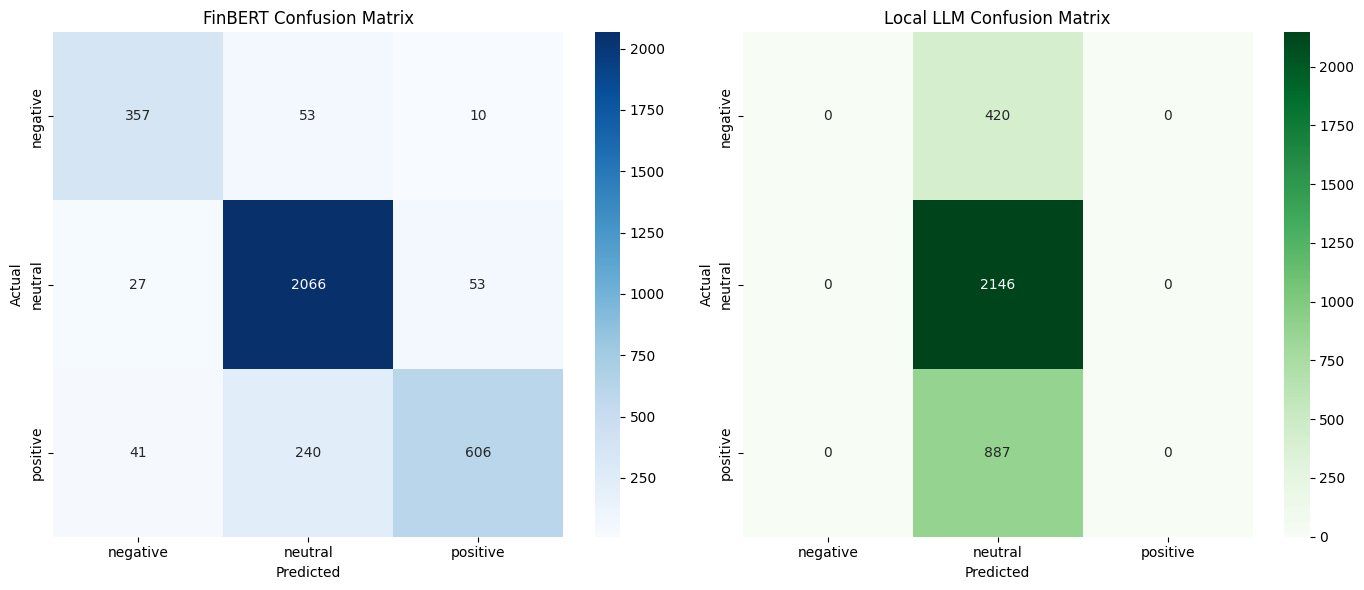

Observations:
- FinBERT Accuracy: 0.8772, Local LLM Accuracy: 0.6215
- FinBERT outperforms the Local LLM on overall accuracy.
- FinBERT is stronger at class 'negative' (F1: 0.84 vs 0.00)
- FinBERT is stronger at class 'neutral' (F1: 0.92 vs 0.77)
- FinBERT is stronger at class 'positive' (F1: 0.78 vs 0.00)


In [29]:
# -----------------------------
# 1. Compute metrics
# -----------------------------
# FinBERT
accuracy_finbert = accuracy_score(data['sentiment'], data['finbert_sentiment'])
report_finbert = classification_report(data['sentiment'], data['finbert_sentiment'], output_dict=True)
cm_finbert = confusion_matrix(data['sentiment'], data['finbert_sentiment'], labels=['negative','neutral','positive'])

# Local LLM
accuracy_llm = accuracy_score(data['sentiment'], data['llm_sentiment'])
report_llm = classification_report(data['sentiment'], data['llm_sentiment'], output_dict=True)
cm_llm = confusion_matrix(data['sentiment'], data['llm_sentiment'], labels=['negative','neutral','positive'])

# -----------------------------
# 2. Create comparison table
# -----------------------------
metrics = ['precision', 'recall', 'f1-score']
classes = ['negative','neutral','positive']

comparison_rows = []

for cls in classes:
    row = {
        'Class': cls,
        'FinBERT Precision': report_finbert[cls]['precision'], # type: ignore
        'LLM Precision': report_llm[cls]['precision'], # type: ignore
        'FinBERT Recall': report_finbert[cls]['recall'], # type: ignore
        'LLM Recall': report_llm[cls]['recall'], # type: ignore
        'FinBERT F1': report_finbert[cls]['f1-score'], # type: ignore
        'LLM F1': report_llm[cls]['f1-score'], # type: ignore
    }
    comparison_rows.append(row)

# Overall Accuracy
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.loc[len(comparison_df)] = {
    'Class': 'Overall Accuracy',
    'FinBERT Precision': accuracy_finbert,
    'LLM Precision': accuracy_llm,
    'FinBERT Recall': '-',
    'LLM Recall': '-',
    'FinBERT F1': '-',
    'LLM F1': '-'
}

print("FinBERT vs Local LLM Metric Comparison:")
display(comparison_df)

# -----------------------------
# 3. Plot side-by-side confusion matrices
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(14,6))

sns.heatmap(cm_finbert, annot=True, fmt='d', ax=axes[0], cmap='Blues',
            xticklabels=classes, yticklabels=classes)
axes[0].set_title("FinBERT Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_llm, annot=True, fmt='d', ax=axes[1], cmap='Greens',
            xticklabels=classes, yticklabels=classes)
axes[1].set_title("Local LLM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# -----------------------------
# 4. Print observations automatically
# -----------------------------
print("Observations:")
print(f"- FinBERT Accuracy: {accuracy_finbert:.4f}, Local LLM Accuracy: {accuracy_llm:.4f}")
if accuracy_finbert > accuracy_llm:
    print("- FinBERT outperforms the Local LLM on overall accuracy.")
elif accuracy_finbert < accuracy_llm:
    print("- Local LLM outperforms FinBERT on overall accuracy.")
else:
    print("- Both models have the same overall accuracy.")

for cls in classes:
    f1_finbert = report_finbert[cls]['f1-score'] # type: ignore
    f1_llm = report_llm[cls]['f1-score'] # type: ignore
    if f1_finbert > f1_llm:
        print(f"- FinBERT is stronger at class '{cls}' (F1: {f1_finbert:.2f} vs {f1_llm:.2f})")
    elif f1_finbert < f1_llm:
        print(f"- Local LLM is stronger at class '{cls}' (F1: {f1_llm:.2f} vs {f1_finbert:.2f})")
    else:
        print(f"- Both models perform equally at class '{cls}' (F1: {f1_finbert:.2f})")

### **C. RAG-Enhanced Sentiment Analysis**

***• Create sentence embeddings (SentenceTransformers or similar)***

***• Build a FAISS index***

In [48]:
## 1. Create Sentence Embeddings (SentenceTransformers)

from sentence_transformers import SentenceTransformer
import faiss

print("Loading Sentence Transformer model...")
# Choose an efficient and good-quality model
# all-MiniLM-L6-v2 is fast, small (~80MB), and produces 384-dim embeddings
embedder = SentenceTransformer('all-MiniLM-L6-v2')

# Generate embeddings for ALL original sentences
# We use the original sentence as the knowledge source is the sentence itself
corpus_sentences = data['sentence'].tolist()
corpus_embeddings = embedder.encode(corpus_sentences, convert_to_tensor=False, show_progress_bar=True)

# Convert to float32 numpy array, which is required by FAISS
corpus_embeddings = np.array(corpus_embeddings).astype('float32')

# Get dimensions (384 for all-MiniLM-L6-v2)
D = corpus_embeddings.shape[1]
print(f"Embeddings shape: {corpus_embeddings.shape}")


## 2. Build a FAISS Index

# IndexFlatL2 is a simple, exact search index using L2 (Euclidean) distance.
# Since we are using the CPU version, we use the standard faiss.IndexFlatL2
index = faiss.IndexFlatL2(D)

# Add the embeddings to the index
index.add(corpus_embeddings)

print(f"FAISS index built. Total vectors: {index.ntotal}")

Loading Sentence Transformer model...


Batches: 100%|██████████| 108/108 [00:01<00:00, 79.78it/s]


Embeddings shape: (3453, 384)
FAISS index built. Total vectors: 3453


***• For each sentence:
o Retrieve top-k similar sentences
o Provide retrieved context to an LLM
o Let the LLM produce a sentiment output***

In [ ]:
# Re-using the Local LLM loaded in Task 3.B
# llm_pipeline is assumed to be available
# llm_pipeline = pipeline("text-generation", model=model, tokenizer=tokenizer)

K = 5 # Number of nearest neighbors to retrieve

# Define RAG-Enhanced Sentiment Prompt
def get_rag_prompt(query_sentence, retrieved_context):
    """
    Formats the prompt to include the retrieved similar examples.
    """
    context_str = "\n".join([
        f"Context Sentence: \"{sent}\" | Ground Truth Sentiment: {sent_label}"
        for sent, sent_label in retrieved_context
    ])
    
    prompt = f"""
You are a financial sentiment classifier. Analyze the provided context of similar financial sentences and their known sentiments to help classify the sentiment of the NEW SENTENCE.

---
CONTEXT (Similar Examples):
{context_str}
---
NEW SENTENCE:
Classify the sentiment of the following financial sentence as Positive, Neutral, or Negative:
"{query_sentence}"
Sentiment:
"""
    return prompt.strip()

# New column for RAG sentiment
data["rag_sentiment"] = ""

for idx, row in tqdm(data.iterrows(), total=len(data), desc="RAG-Enhanced Sentiment Analysis"):
    query_sentence = row["sentence"]
    
    # 1. Retrieve top-K similar sentences
    query_embedding = embedder.encode([query_sentence]).astype('float32')
    
    # D: distances, I: indices of the nearest neighbors
    D_faiss, I_faiss = index.search(query_embedding, K + 1) # Search for K+1 to exclude the query itself (index 0)
    
    # The query sentence itself will almost always be the closest neighbor (index 0).
    # We skip the first result to get only the true neighbors.
    neighbor_indices = I_faiss[0][1:] 
    
    # Retrieve the sentences and their ground truth sentiments
    retrieved_context = [
        (data.iloc[i]['sentence'], data.iloc[i]['sentiment'])
        for i in neighbor_indices
    ]
    
    # 2. Provide retrieved context to the LLM
    prompt = get_rag_prompt(query_sentence, retrieved_context)
    
    # 3. Let the LLM produce a sentiment output
    result = llm_pipeline(prompt, max_new_tokens=10, do_sample=False)
    
    # Extract output text and normalize (same cleaning logic as Task B)
    output_text = result[0]['generated_text'].split("Sentiment:")[-1].strip().lower()
    
    # Apply cleaning and mapping
    final_sentiment = mapping.get(output_text, 'neutral') # Use the same mapping dict from Task 3.B

    # Store in DataFrame
    data.at[idx, "rag_sentiment"] = final_sentiment # type: ignore

print("\nRAG Sentiment Sample Predictions:")
display(data[['sentence', 'sentiment', 'llm_sentiment', 'rag_sentiment']].sample(5))

RAG-Enhanced Sentiment Analysis: 100%|██████████| 3453/3453 [09:41<00:00,  5.94it/s]


RAG Sentiment Sample Predictions:


,sentence,sentiment,llm_sentiment,rag_sentiment
393,Jan. 6 -- Ford is struggling in the face of sl...,negative,neutral,neutral
2357,The value of the order is nearly EUR400m .,neutral,neutral,neutral
2431,`` Because we 're a pension insurance company ...,neutral,neutral,neutral
2672,The company expects its net sales for the whol...,neutral,neutral,neutral
2137,Talvivaara Mining Company Plc Talvivaara Minin...,neutral,neutral,neutral


In [85]:
import numpy as np

# Save the sentence embeddings
# NOTE: Ensure 'corpus_embeddings' variable is available from your script
np.save('corpus_embeddings.npy', corpus_embeddings)

print("✅ Embeddings saved to: corpus_embeddings.npy")

✅ Embeddings saved to: corpus_embeddings.npy


In [86]:
import faiss
import os

# Define the file path for the FAISS index
faiss_index_path = 'faiss_index.bin'

# Save the FAISS index
# NOTE: Ensure 'index' variable is available from your script
faiss.write_index(index, faiss_index_path)

print(f"✅ FAISS index saved to: {faiss_index_path}")

✅ FAISS index saved to: faiss_index.bin


In [87]:
# Save the final DataFrame containing all results
# NOTE: Ensure 'data' DataFrame is available from your script
data.to_csv('financial_sentiment_results.csv', index=False, encoding='utf-8')

print("✅ Results DataFrame saved to: financial_sentiment_results.csv")

✅ Results DataFrame saved to: financial_sentiment_results.csv


RAG Accuracy: 0.6215
RAG Classification Report:
               precision    recall  f1-score   support

    negative       0.00      0.00      0.00       420
     neutral       0.62      1.00      0.77      2146
    positive       0.00      0.00      0.00       887

    accuracy                           0.62      3453
   macro avg       0.21      0.33      0.26      3453
weighted avg       0.39      0.62      0.48      3453

RAG Confusion Matrix:
 [[   0  420    0]
 [   0 2146    0]
 [   0  887    0]]

--- FinBERT vs Local LLM vs RAG Metric Comparison ---


,Class,FinBERT F1,LLM F1,RAG F1
0,negative,0.844970,0.000000,0.000000
1,neutral,0.917203,0.766565,0.766565
2,positive,0.778920,0.000000,0.000000
3,Overall Accuracy,0.877208,0.621489,0.621489


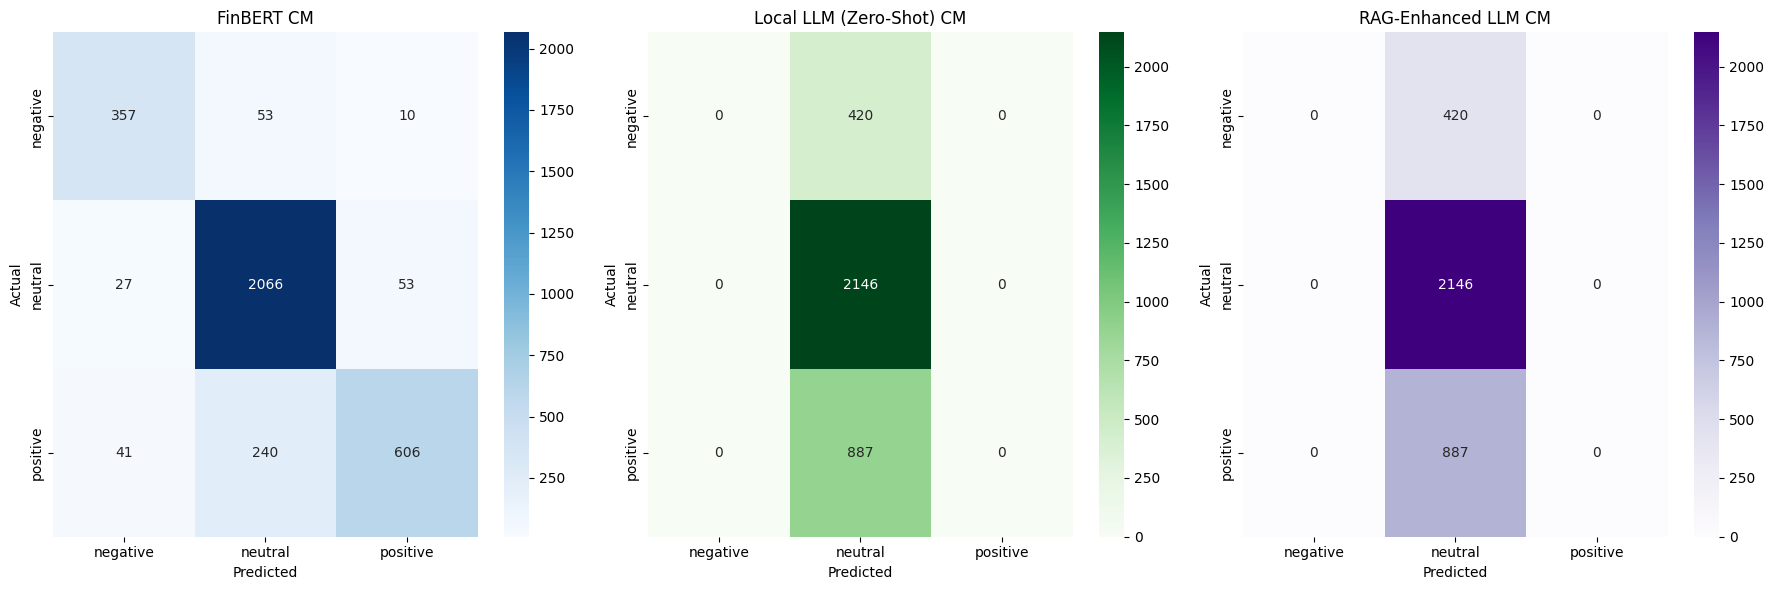

Final Observations on Model Performance:
- FinBERT Accuracy: 0.8772
- Local LLM (Zero-Shot) Accuracy: 0.6215
- RAG-Enhanced LLM Accuracy: 0.6215

Overall Best Performer: **FinBERT**


In [50]:
# -----------------------------
# 1. Compute metrics for RAG
# -----------------------------
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_rag = accuracy_score(data['sentiment'], data['rag_sentiment'])
print(f"RAG Accuracy: {accuracy_rag:.4f}")

report_rag = classification_report(data['sentiment'], data['rag_sentiment'], target_names=['negative', 'neutral', 'positive'], output_dict=True)
print("RAG Classification Report:\n", classification_report(data['sentiment'], data['rag_sentiment'], target_names=['negative', 'neutral', 'positive']))

cm_rag = confusion_matrix(data['sentiment'], data['rag_sentiment'], labels=['negative', 'neutral', 'positive'])
print("RAG Confusion Matrix:\n", cm_rag)


# -----------------------------
# 2. Update Comparison Table
# -----------------------------
metrics = ['precision', 'recall', 'f1-score']
classes = ['negative','neutral','positive']

rag_comparison_rows = []

for cls in classes:
    row = {
        'Class': cls,
        'FinBERT F1': report_finbert[cls]['f1-score'], # type: ignore
        'LLM F1': report_llm[cls]['f1-score'], # type: ignore
        'RAG F1': report_rag[cls]['f1-score'], # type: ignore
    }
    rag_comparison_rows.append(row)

# Overall Accuracy
rag_comparison_df = pd.DataFrame(rag_comparison_rows)
rag_comparison_df.loc[len(rag_comparison_df)] = {
    'Class': 'Overall Accuracy',
    'FinBERT F1': accuracy_finbert,
    'LLM F1': accuracy_llm,
    'RAG F1': accuracy_rag
}

print("\n--- FinBERT vs Local LLM vs RAG Metric Comparison ---")
display(rag_comparison_df)

# -----------------------------
# 3. Plot all three confusion matrices
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# FinBERT
sns.heatmap(cm_finbert, annot=True, fmt='d', ax=axes[0], cmap='Blues',
            xticklabels=classes, yticklabels=classes)
axes[0].set_title("FinBERT CM")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Local LLM
sns.heatmap(cm_llm, annot=True, fmt='d', ax=axes[1], cmap='Greens',
            xticklabels=classes, yticklabels=classes)
axes[1].set_title("Local LLM (Zero-Shot) CM")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

# RAG LLM
sns.heatmap(cm_rag, annot=True, fmt='d', ax=axes[2], cmap='Purples',
            xticklabels=classes, yticklabels=classes)
axes[2].set_title("RAG-Enhanced LLM CM")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()


# -----------------------------
# 4. Final Observations
# -----------------------------
print("Final Observations on Model Performance:")
print(f"- FinBERT Accuracy: {accuracy_finbert:.4f}")
print(f"- Local LLM (Zero-Shot) Accuracy: {accuracy_llm:.4f}")
print(f"- RAG-Enhanced LLM Accuracy: {accuracy_rag:.4f}")

best_model = max([
    ('FinBERT', accuracy_finbert), 
    ('LLM', accuracy_llm), 
    ('RAG', accuracy_rag)
], key=lambda x: x[1])[0]

print(f"\nOverall Best Performer: **{best_model}**")

if accuracy_rag > accuracy_llm and accuracy_rag > accuracy_finbert:
    print("- RAG provides a strong improvement, suggesting that using ground-truth context from similar sentences effectively guides the LLM to the correct classification.")
elif accuracy_rag > accuracy_llm:
    print("- RAG-Enhanced LLM is better than the Zero-Shot LLM, demonstrating the value of contextual retrieval.")

# **Task 5:Fine-Tuning Rule**

No method hit ≥ 90% accuracy → Fine-tuning is required.

Candidate models to fine-tune: FinBERT (recommended, smaller and faster) or your LLM (requires huge GPU, slower).

In [67]:
import torch
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd


In [68]:
dataset_path = "dataset/FinancialPhraseBank-v1.0/Sentences_75Agree.txt"
data = pd.read_csv(dataset_path, sep='@', header=None, names=['sentence', 'sentiment'], engine='python', encoding='latin1')

# Inspect
data.head()


,sentence,sentiment
0,"According to Gran , the company has no plans t...",neutral
1,With the new production plant the company woul...,positive
2,"For the last quarter of 2010 , Componenta 's n...",positive
3,"In the third quarter of 2010 , net sales incre...",positive
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive


In [69]:
label_mapping = {"negative": 0, "neutral": 1, "positive": 2}
data['label'] = data['sentiment'].map(label_mapping)


In [70]:
train_texts, val_texts, train_labels, val_labels = train_test_split(
    data['sentence'].tolist(),
    data['label'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=data['label']
)


In [71]:
tokenizer = BertTokenizer.from_pretrained("yiyanghkust/finbert-tone")

train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=128)
val_encodings = tokenizer(val_texts, truncation=True, padding=True, max_length=128)


In [72]:
class FinanceDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

train_dataset = FinanceDataset(train_encodings, train_labels)
val_dataset = FinanceDataset(val_encodings, val_labels)


In [73]:
model = BertForSequenceClassification.from_pretrained("yiyanghkust/finbert-tone", num_labels=3)


In [75]:
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    acc = accuracy_score(labels, preds)
    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }


In [78]:
training_args = TrainingArguments(
    output_dir="./finbert_finetuned",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    logging_dir="./logs",
    logging_steps=50,
    do_eval=True,      # old syntax
    eval_steps=200,
    save_steps=200,
    save_total_limit=2,
    fp16=True
    # load_best_model_at_end removed
)


In [79]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)


In [80]:
trainer.train()


Step,Training Loss
50,2.429500
100,0.477200
150,0.411100
200,0.310400
250,0.154100
300,0.181600
350,0.126000
400,0.050600
450,0.048100
500,0.044200


TrainOutput(global_step=519, training_loss=0.4107495479730742, metrics={'train_runtime': 51.2873, 'train_samples_per_second': 161.561, 'train_steps_per_second': 10.119, 'total_flos': 528006962172816.0, 'train_loss': 0.4107495479730742, 'epoch': 3.0})

In [81]:
trainer.evaluate()


{'eval_loss': 0.2359178215265274,
 'eval_accuracy': 0.9218523878437048,
 'eval_precision': 0.9232484526682354,
 'eval_recall': 0.9218523878437048,
 'eval_f1': 0.9223854515009987,
 'eval_runtime': 1.1881,
 'eval_samples_per_second': 581.6,
 'eval_steps_per_second': 37.034,
 'epoch': 3.0}

In [83]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Make predictions on validation set
preds_output = trainer.predict(val_dataset)
preds = np.argmax(preds_output.predictions, axis=1)
labels = np.array(val_labels)

# Classification report
report = classification_report(labels, preds, target_names=["negative", "neutral", "positive"])
print("Classification Report:\n", report)

# Confusion matrix
cm = confusion_matrix(labels, preds)
print("Confusion Matrix:\n", cm)

# Accuracy
accuracy = np.sum(preds == labels) / len(labels)
print("Accuracy:", round((accuracy*100), 4))


Classification Report:
               precision    recall  f1-score   support

    negative       0.85      0.87      0.86        84
     neutral       0.96      0.94      0.95       429
    positive       0.86      0.89      0.88       178

    accuracy                           0.92       691
   macro avg       0.89      0.90      0.90       691
weighted avg       0.92      0.92      0.92       691

Confusion Matrix:
 [[ 73   2   9]
 [  7 405  17]
 [  6  13 159]]
Accuracy: 92.1852


In [84]:
from transformers import BertForSequenceClassification, BertTokenizer

# Save the fine-tuned model
model.save_pretrained("./finbert_finetuned")
tokenizer.save_pretrained("./finbert_finetuned")

# Save your dataset with predictions
data.to_csv("finbert_finetuned_results.csv", index=False)
